# SBML Simulation and Validation of AI-Generated BioCRNpyler Models

This notebook serves as the second phase of evaluating Large Language Models (including Gemini NIST version, Claude, and ChatGPT) on their ability to automate biological modeling. While the first notebook tested raw Python code generation, this notebook validates the resulting SBML files to ensure they run correctly and accurately represent the target circuit.

**Target Model:** The models are evaluated on their ability to simulate a Chemical Reaction Network (CRN) representing the DNA strand displacement **AND gate** detailed in *Programming Cell-free Biosensors with DNA Strand Displacement Circuits* ([Jung et al., Nature Chemical Biology 2022](https://www.nature.com/articles/s41589-021-00962-9)).

## Simulation Methodology

To rigorously and fairly assess the functional logic of each generated model, the testing followed this procedure:

* **SBML Import:** The generated `.xml` (SBML) files from successful AI runs were loaded into the simulator.
* **Manual Initial Conditions & Mapping:** Because different AI generators hallucinated or chose different naming conventions for the same biological species (e.g., varying abbreviations or formatting), initial conditions were instantiated and manually mapped to fit each model's specific nomenclature. This manual adjustment ensures the underlying mathematical logic is tested fairly, regardless of naming quirks.
* **Sequential Simulation:** The models were simulated in order to observe their dynamics and verify if the expected AND gate behavior was achieved. 
* **Error Retention:** If an SBML file contained structural errors and failed to simulate, the resulting traceback was retained, and execution naturally continued to the next model.

*Note: Gemini generation was performed using the NIST version of Gemini on the [Pro] option. Claude and ChatGPT script generation was performed using their respective Free Plans.*

## Global variables, definitions, and dependencies

In [1]:
#General
import numpy as np
import glob
import pandas as pd

#From bioscrape
from bioscrape.simulator import py_simulate_model
from bioscrape.types import Model
import matplotlib.pyplot as plt

from pathlib import Path
# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Directory for models
model_dir = (base_dir / 'models' / 'AI_generated models').as_posix()

In [2]:
# Simulate all models - example for 12 hours
timepoints = np.linspace(0,12,1001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (8.27, 6)

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.25, ymax = 25):
    fs = 22
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.xlabel('Time (h)',fontsize=22)
    plt.ylim(ymin,ymax)
    plt.xlim(0,12)

    plt.ylim(ymin,ymax)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)

    # # Save plot as svg
    # plt.savefig(f'{directory}/main_{fig_name}.svg')

colors=['#b3cde3','#8c96c6','#8856a7', '#810f7c']

# Initialize the empty DataFrame to store all simulation results
all_simulation_df = pd.DataFrame(columns=[
    'Model_Name', 
    'Condition', 
    'Time', 
    'Reporter_Concentration'
])

## Gemini Simulations

C:\Users\zej1\AppData\Local\Temp\ipykernel_24272\3543495363.py:47: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_simulation_df = pd.concat([all_simulation_df, temp_df], ignore_index=True)


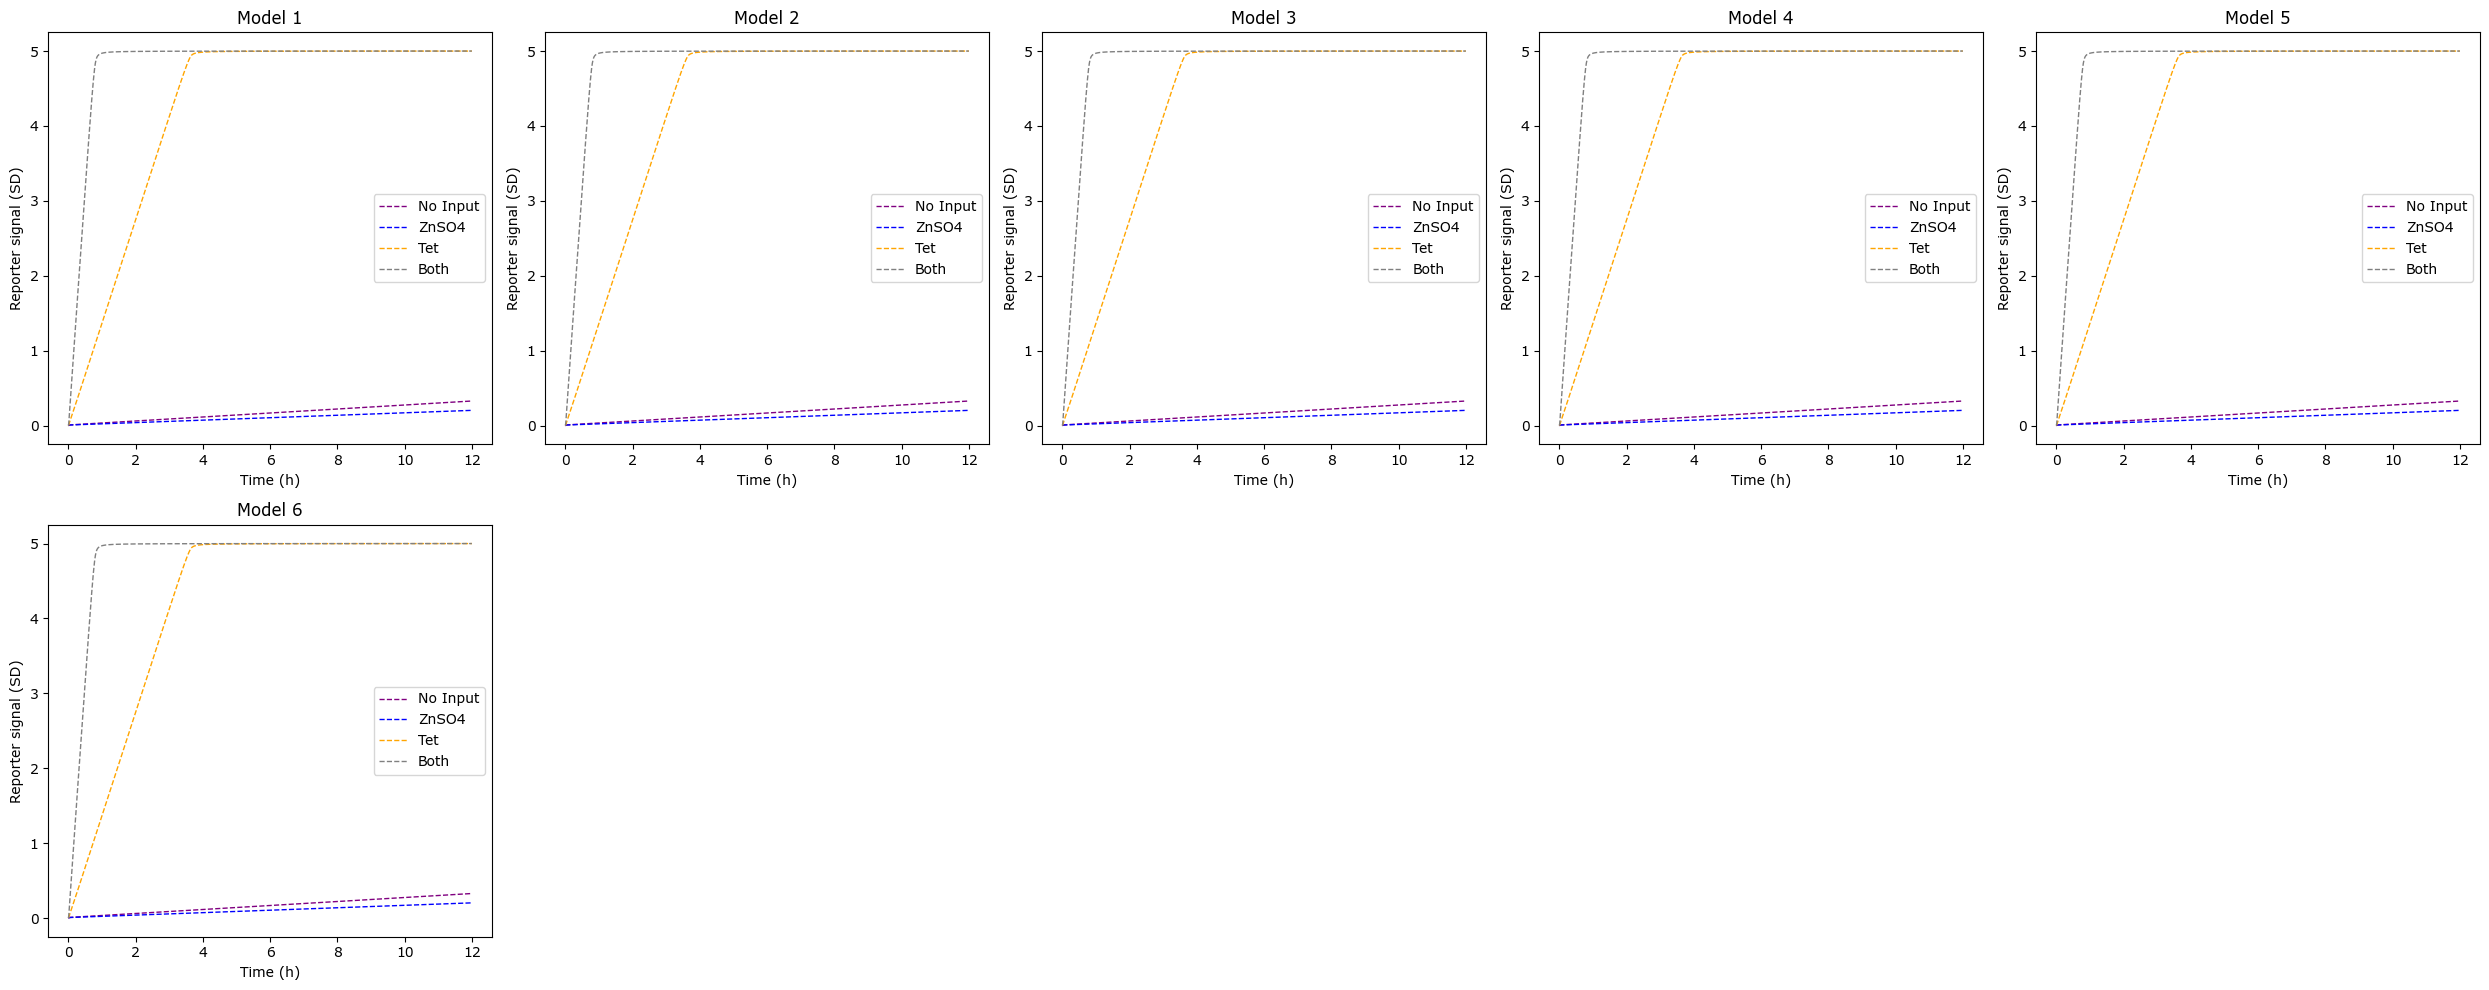

In [3]:
# List of model
gemini_models_prefix = 'AND_gate_CRN_gemini_*'
gemini_models = sorted(glob.glob(f"{model_dir}/{gemini_models_prefix}") )

# Initialize the figure
plt.figure(figsize=(25, 10))

# Enumerate to get an index for the subplots
for i, model in enumerate(gemini_models, start=1):
    m = Model(sbml_filename=model)

    # Specific subplot
    plt.subplot(2, 5, i)
    plt.title(f"Model {i}")

    # Input templates
    tet = [0,0,1,1]
    Zn = [0,1,0,1]

    idx_conditions = {'No Input':['purple', '--'],
                      'ZnSO4': ['blue','--'],
                      'Tet': ['orange','--'],
                      'Both': ['grey','--']}

    for tet_conc, zn_conc, color, key in zip(tet,Zn, colors, idx_conditions):
        m.set_species({"tet": tet_conc*10,
                       "D_tetO": 0.05, "D_smtO": 0.05, "RNAP": 0.1,
                       "TetR": 3.75, "SmtB": 3.75, "Zn": zn_conc*10,
                       "AND_Gate": 5, "RQ": 5})

        color = idx_conditions[key][0]
        linestyle = idx_conditions[key][1]

        R1 = py_simulate_model(Model=m, timepoints=timepoints)

        # Plot the simulation results
        plt.plot(R1['time']/3600, R1['SD'], color=color, linewidth=1,
                 label=f"{key}", linestyle=linestyle)
        
        # Create a temporary DataFrame
        temp_df = pd.DataFrame({
            'Model_Name': f'Gemini_m{i}',
            'Condition': key,
            'Time': R1['time'],
            'Reporter_Concentration': R1['SD'] 
        })
        all_simulation_df = pd.concat([all_simulation_df, temp_df], ignore_index=True)

    # Formatting
    plt.xlabel('Time (h)')
    plt.ylabel('Reporter signal (SD)')
    plt.legend()

#  Clean up layout
plt.tight_layout()
plt.show()

## ChatGPT Simulations

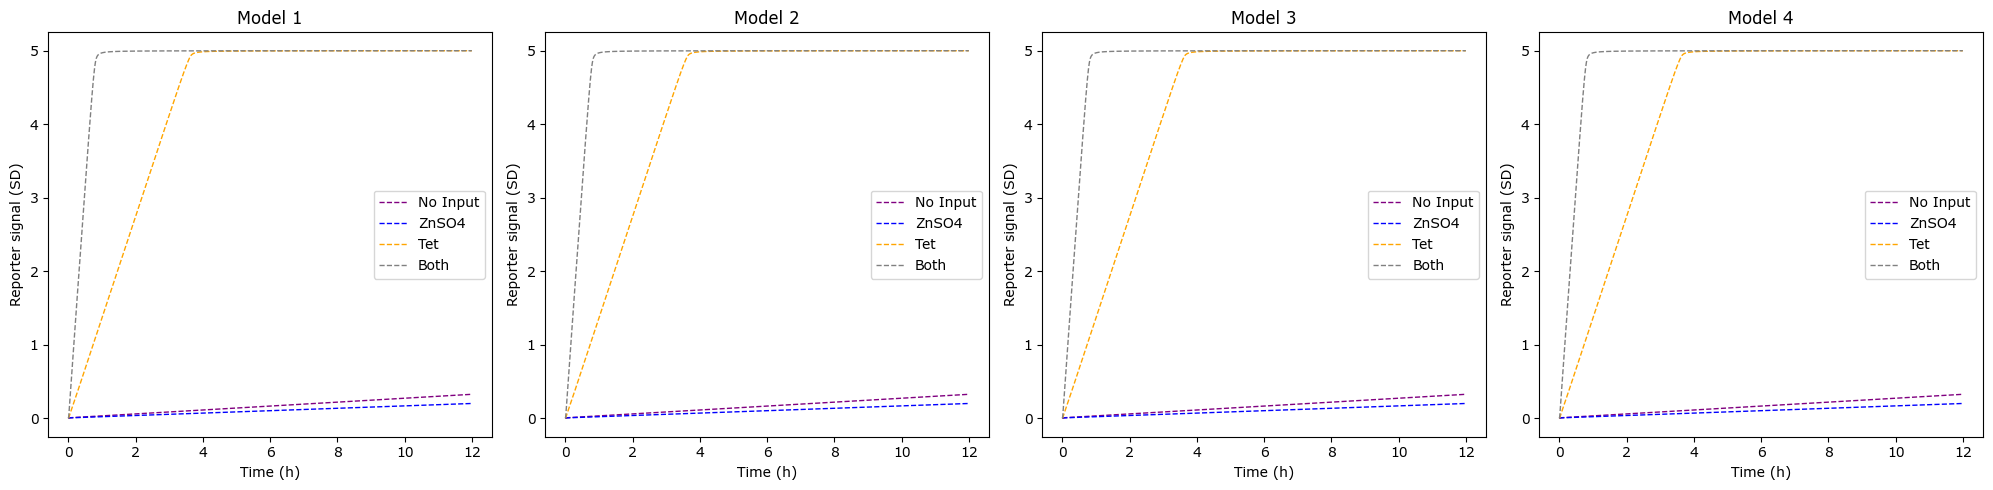

In [4]:
# List of models
chatgpt_models_prefix = 'AND_gate_CRN_chatgpt_*'
chatgpt_models = sorted(glob.glob(f"{model_dir}/{chatgpt_models_prefix}") )

# Initialize the figure
plt.figure(figsize=(25, 5))

# Enumerate to get an index for the subplots
for i, model in enumerate(chatgpt_models, start=1):
    m = Model(sbml_filename=model)

    # Specific subplot
    plt.subplot(1, 5, i)
    plt.title(f"Model {i}")

    # Input templates
    tet = [0,0,1,1]
    Zn = [0,1,0,1]

    idx_conditions = {'No Input':['purple', '--'],
                      'ZnSO4': ['blue','--'],
                      'Tet': ['orange','--'],
                      'Both': ['grey','--']}

    for tet_conc, zn_conc, color, key in zip(tet,Zn, colors,idx_conditions):
        # adjusted initial conditions based on model species name
        if i == 1 or i==4:
            m.set_species({"tet": tet_conc*10,
                       "dna_D_tetO": 0.05, "dna_D_smtO": 0.05, "protein_RNAP": 0.1,
                       "protein_TetR": 3.75, "protein_SmtB": 3.75, "Zn": zn_conc*10,
                       "AND_Gate": 5, "RQ": 5})
        elif i==2:
             m.set_species({"tet": tet_conc*10,
                       "D_tetO": 0.05, "D_smtO": 0.05, "RNAP": 0.1,
                       "TetR": 3.75, "SmtB": 3.75, "Zn": zn_conc*10,
                       "AND_Gate": 5, "RQ": 5})
        else:
            m.set_species({"small_molecule_tet": tet_conc*10,
                       "dna_D_tetO": 0.05, "dna_D_smtO": 0.05, "protein_RNAP": 0.1,
                       "protein_TetR": 3.75, "protein_SmtB": 3.75, "small_molecule_Zn": zn_conc*10,
                       "AND_Gate": 5, "RQ": 5})

        color = idx_conditions[key][0]
        linestyle = idx_conditions[key][1]

        R1 = py_simulate_model(Model=m, timepoints=timepoints)

        # Plot the simulation results
        plt.plot(R1['time']/3600, R1['SD'], color=color, linewidth=1,
                 label=f"{key}", linestyle=linestyle)
        
        # Create a temporary DataFrame
        temp_df = pd.DataFrame({
            'Model_Name': f'ChatGPT_m{i}',
            'Condition': key,
            'Time': R1['time'],
            'Reporter_Concentration': R1['SD'] 
        })
        all_simulation_df = pd.concat([all_simulation_df, temp_df], ignore_index=True)

    # Formatting
    plt.xlabel('Time (h)')
    plt.ylabel('Reporter signal (SD)')
    plt.legend()

# Clean up layout
plt.tight_layout()
plt.show()

## Claude Simulations

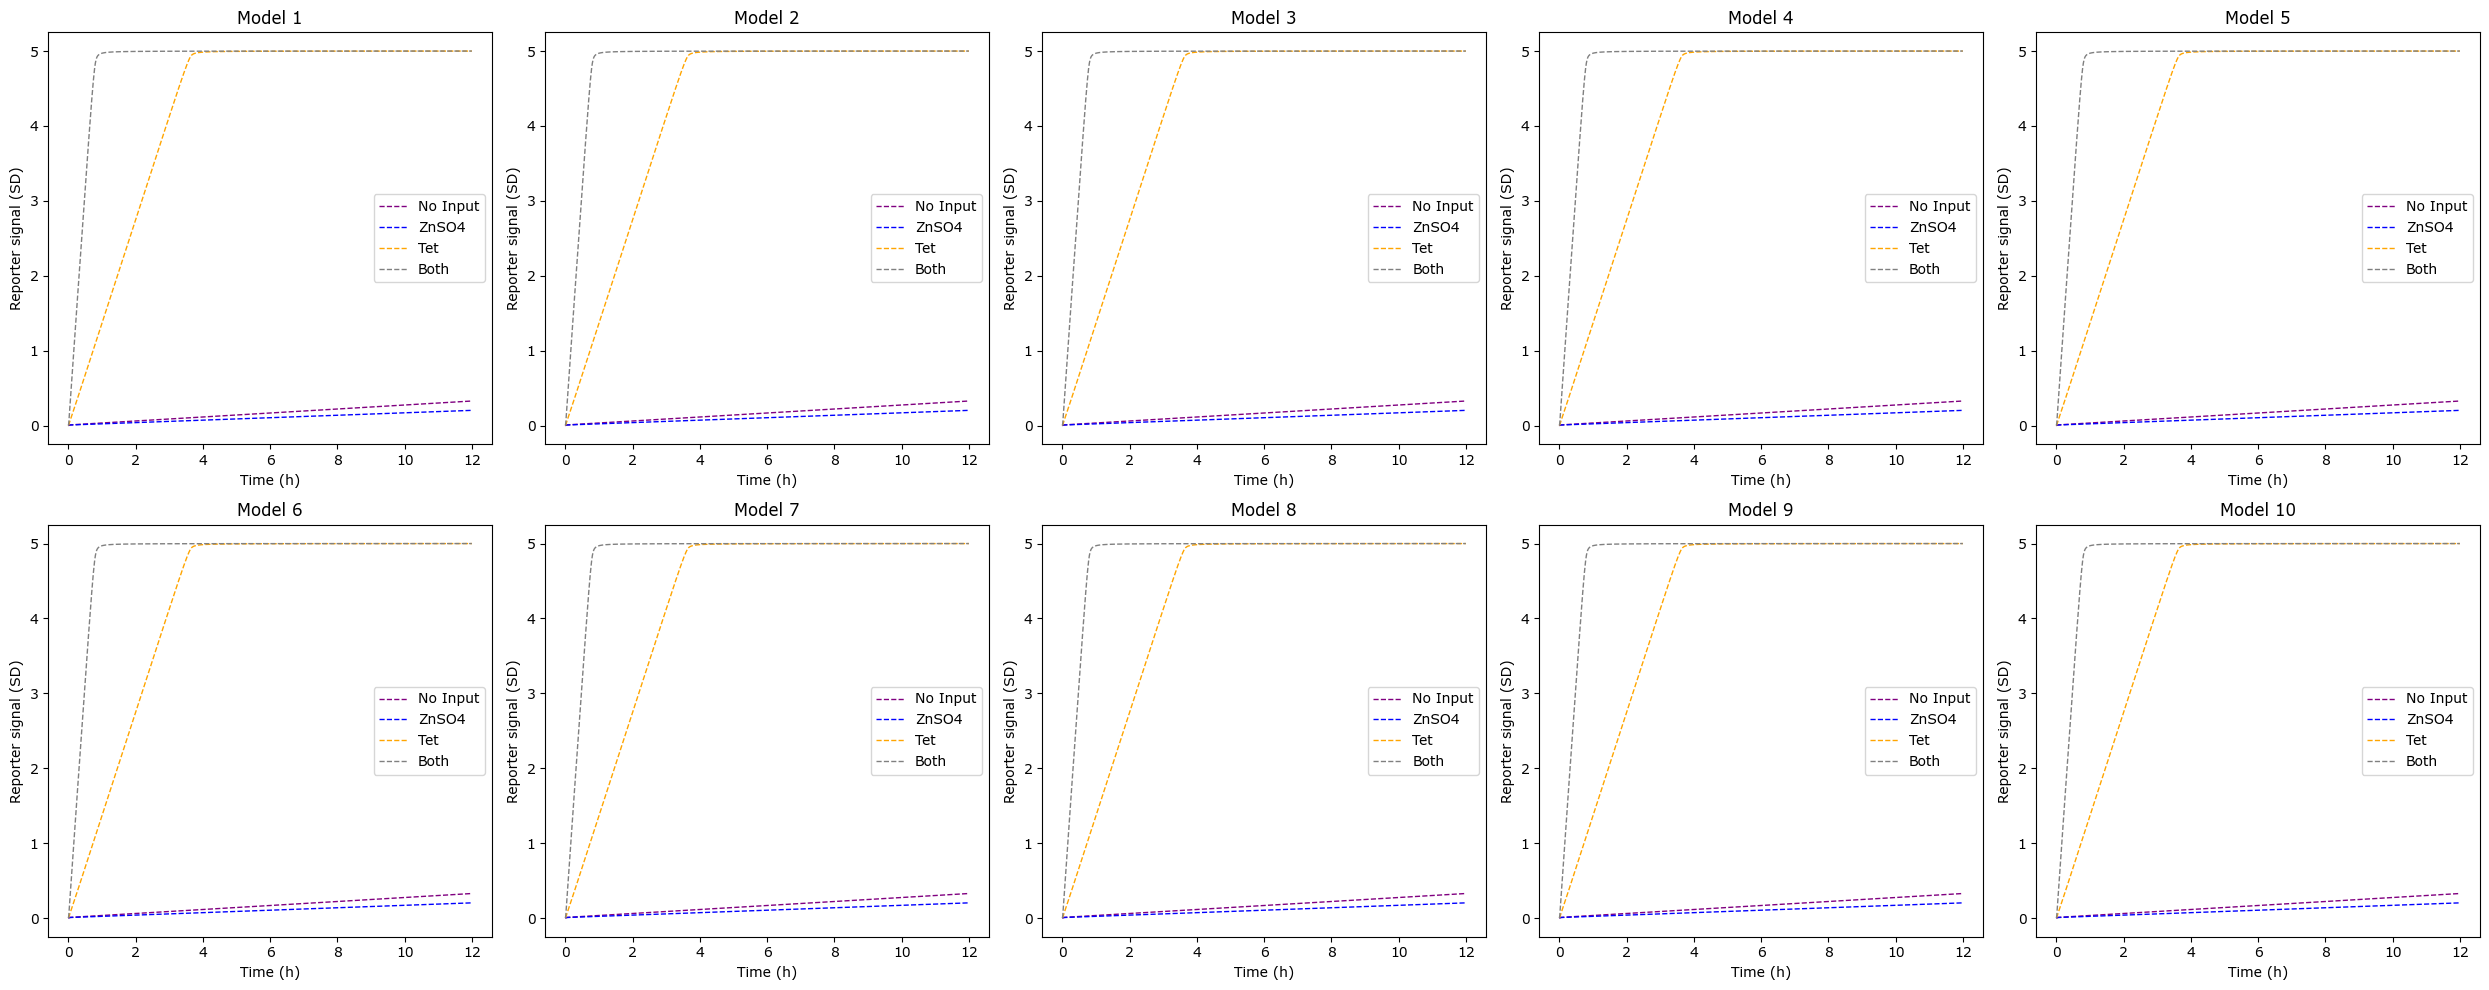

In [5]:
# List of models
claude_models_prefix = 'AND_gate_CRN_claude_*'
claude_models = sorted(glob.glob(f"{model_dir}/{claude_models_prefix}") )

# Initialize the figure 
plt.figure(figsize=(25, 10))

# Enumerate to get an index for the subplots
for i, model in enumerate(claude_models, start=1):
    m = Model(sbml_filename=model)
    
    # Specific subplot
    plt.subplot(2, 5, i)
    plt.title(f"Model {i}")

    # Input templates
    tet = [0,0,1,1]
    Zn = [0,1,0,1]

    idx_conditions = {'No Input':['purple', '--'],
                      'ZnSO4': ['blue','--'],
                      'Tet': ['orange','--'],
                      'Both': ['grey','--']}

    for tet_conc, zn_conc, color, key in zip(tet,Zn, colors,idx_conditions):
        if i == 1 or i==3 or i==6 or i==7:
            m.set_species({"tet": tet_conc*10,
                       "D_tetO": 0.05, "D_smtO": 0.05, "RNAP": 0.1,
                       "TetR": 3.75, "SmtB": 3.75, "Zn": zn_conc*10,
                       "AND_Gate": 5, "RQ": 5})
        elif i==2 or i==5 or i==10:
            m.set_species({"small_molecule_tet": tet_conc*10,
                       "dna_D_tetO": 0.05, "dna_D_smtO": 0.05, "protein_RNAP": 0.1,
                       "protein_TetR": 3.75, "protein_SmtB": 3.75, "small_molecule_Zn": zn_conc*10,
                       "dna_AND_Gate": 5, "complex_RQ": 5})
        elif i==4:
            m.set_species({"small_molecule_tet": tet_conc*10,
                       "dna_D_tetO": 0.05, "dna_D_smtO": 0.05, "protein_RNAP": 0.1,
                       "protein_TetR": 3.75, "protein_SmtB": 3.75, "small_molecule_Zn": zn_conc*10,
                       "complex_AND_Gate": 5, "complex_RQ": 5})
        elif i==8:
            m.set_species({"smallmol_tet": tet_conc*10,
                       "dna_D_tetO": 0.05, "dna_D_smtO": 0.05, "protein_RNAP": 0.1,
                       "protein_TetR": 3.75, "protein_SmtB": 3.75, "smallmol_Zn": zn_conc*10,
                       "dna_AND_Gate": 5, "complex_RQ": 5})
        else: #i==9:
            m.set_species({"small_molecule_tet": tet_conc*10,
                       "dna_D_tetO": 0.05, "dna_D_smtO": 0.05, "protein_RNAP": 0.1,
                       "protein_TetR": 3.75, "protein_SmtB": 3.75, "small_molecule_Zn": zn_conc*10,
                       "complex_AND_Gate": 5, "complex_RQ": 5})
            
        color = idx_conditions[key][0]
        linestyle = idx_conditions[key][1]

        R1 = py_simulate_model(Model=m, timepoints=timepoints)

        # Plot the simulation results
        sd_species = [s for s in m.get_species() if 'SD' in s] # Find name of reporting species
        plt.plot(R1['time']/3600, R1[sd_species], color=color, linewidth=1,
                 label=f"{key}", linestyle=linestyle)
        
        # Create a temporary DataFrame
        temp_df = pd.DataFrame({
            'Model_Name': f'Claude_m{i}',
            'Condition': key,
            'Time': R1['time'],
            'Reporter_Concentration': R1[sd_species[0]] 
        })
        all_simulation_df = pd.concat([all_simulation_df, temp_df], ignore_index=True)

    # Formatting
    plt.xlabel('Time (h)')
    plt.ylabel('Reporter signal (SD)')
    plt.legend()

# Clean up layout 
plt.tight_layout()
plt.show()

## txt2biocrnpyler Simulations

c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:183: UserWarning: SBML model contains reversible reaction!
Please check rate expressions and ensure they are non-negative before doing stochastic simulations.
  warnings.warn('SBML model contains reversible reaction!\n' +
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:56: UserWarning: Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. Refer to the bioscrape wiki for more information.
  warnings.warn('Compartments, UnitDefintions, Events, and some other SBML model components are not recognized by bioscrape. ' +
c:\Users\zej1\AppData\Local\miniforge3\envs\ctRSD_models\Lib\site-packages\bioscrape\sbmlutil.py:183: UserWarning: SBML model contains reversible reaction!
Please check rate expressions and ensure they are non-negative before doing stochastic simulations.
  warnings.warn('SBML mo

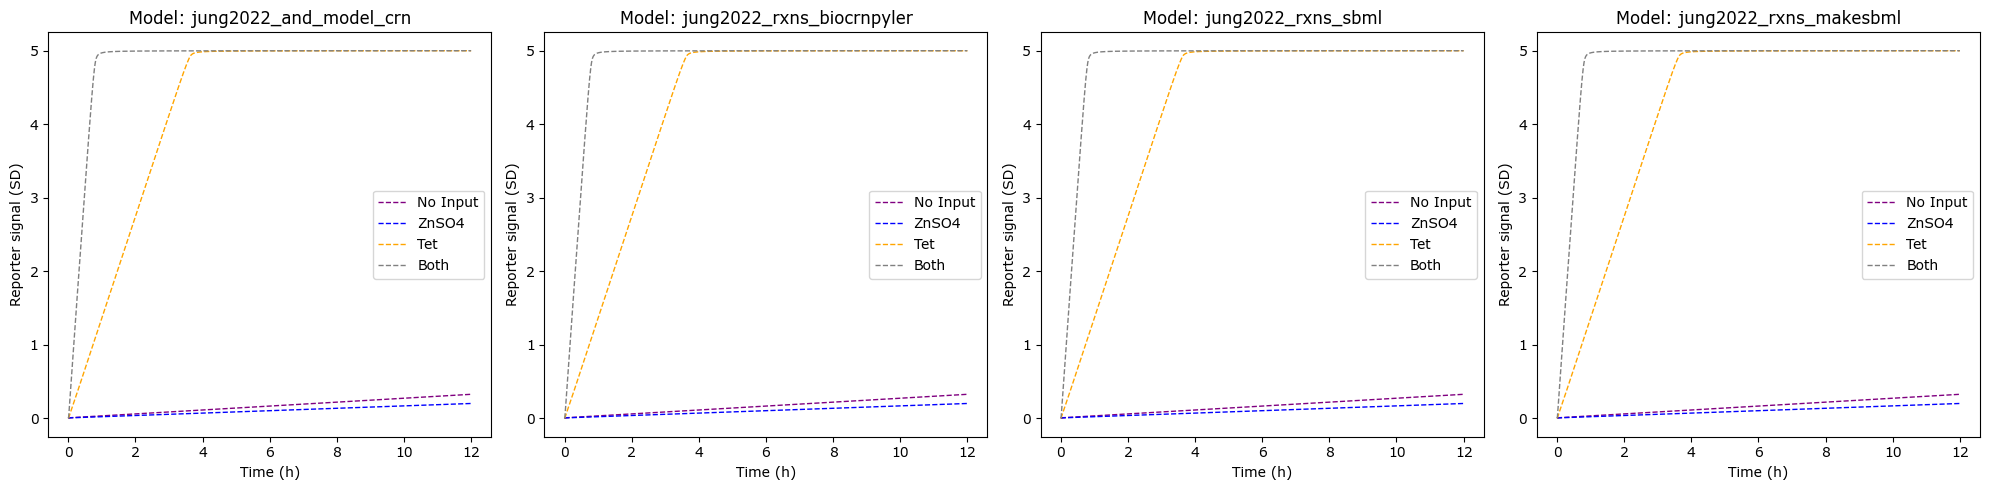

In [6]:
model_dir0 = (base_dir / 'models').as_posix()

# List of model 
model_names = [
    "jung2022_and_model_crn",       # sbml from the biocrnpyler script made by txt2biocrnpyler
    "jung2022_rxns_biocrnpyler",    # sbml directly from txt2biocrnpyler via biocrnpyler
    "jung2022_rxns_sbml" ,           # sbml directly from txt2biocrnpyler
    "jung2022_rxns_makesbml",       # sbml made from Make SBML after running it through gemini again [does not use any part of our model]
]

# Initialize the figure
plt.figure(figsize=(20, 5))

# Enumerate to get an index for the subplots
for index, name in enumerate(model_names, start=1):
    m = Model(sbml_filename=f'{model_dir0}/{name}.xml')

    # Subplot 
    plt.subplot(1, 4, index)
    plt.title(f"Model: {name}")

    # Input templates
    tet = [0, 0, 1, 1]
    Zn = [0, 1, 0, 1]

    idx_conditions = {
        'No Input': ['purple', '--'],
        'ZnSO4': ['blue', '--'],
        'Tet': ['orange', '--'],
        'Both': ['grey', '--']
    }

    # Zip the concentrations with the dictionary keys
    for tet_conc, zn_conc, key in zip(tet, Zn, idx_conditions.keys()):
        # Extract the color and linestyle from the dictionary
        color = idx_conditions[key][0]
        linestyle = idx_conditions[key][1]
        
        m.set_species({"tet": tet_conc * 10,
                       "D_tetO": 0.05, "D_smtO": 0.05, "RNAP": 0.1,
                       "TetR": 3.75, "SmtB": 3.75, "Zn": zn_conc * 10,
                       "AND_Gate": 5, "RQ": 5})

        R1 = py_simulate_model(Model=m, timepoints=timepoints)

        # Plot the simulation results on the active subplot
        plt.plot(R1['time']/3600, R1['SD'], color=color, linewidth=1,
                 label=f"{key}", linestyle=linestyle)
        
        # Create a temporary DataFrame
        short_name = name.replace("jung2022_rxns_", "").replace("jung2022_", "")
        temp_df = pd.DataFrame({
            'Model_Name': f'{short_name}',
            'Condition': key,
            'Time': R1['time'],
            'Reporter_Concentration': R1['SD'] 
        })
        all_simulation_df = pd.concat([all_simulation_df, temp_df], ignore_index=True)

    # Formatting
    plt.xlabel('Time (h)')
    plt.ylabel('Reporter signal (SD)')
    plt.legend()

# Clean up layout 
plt.tight_layout()
plt.show()

## Model Comparison Across Simulation Conditions

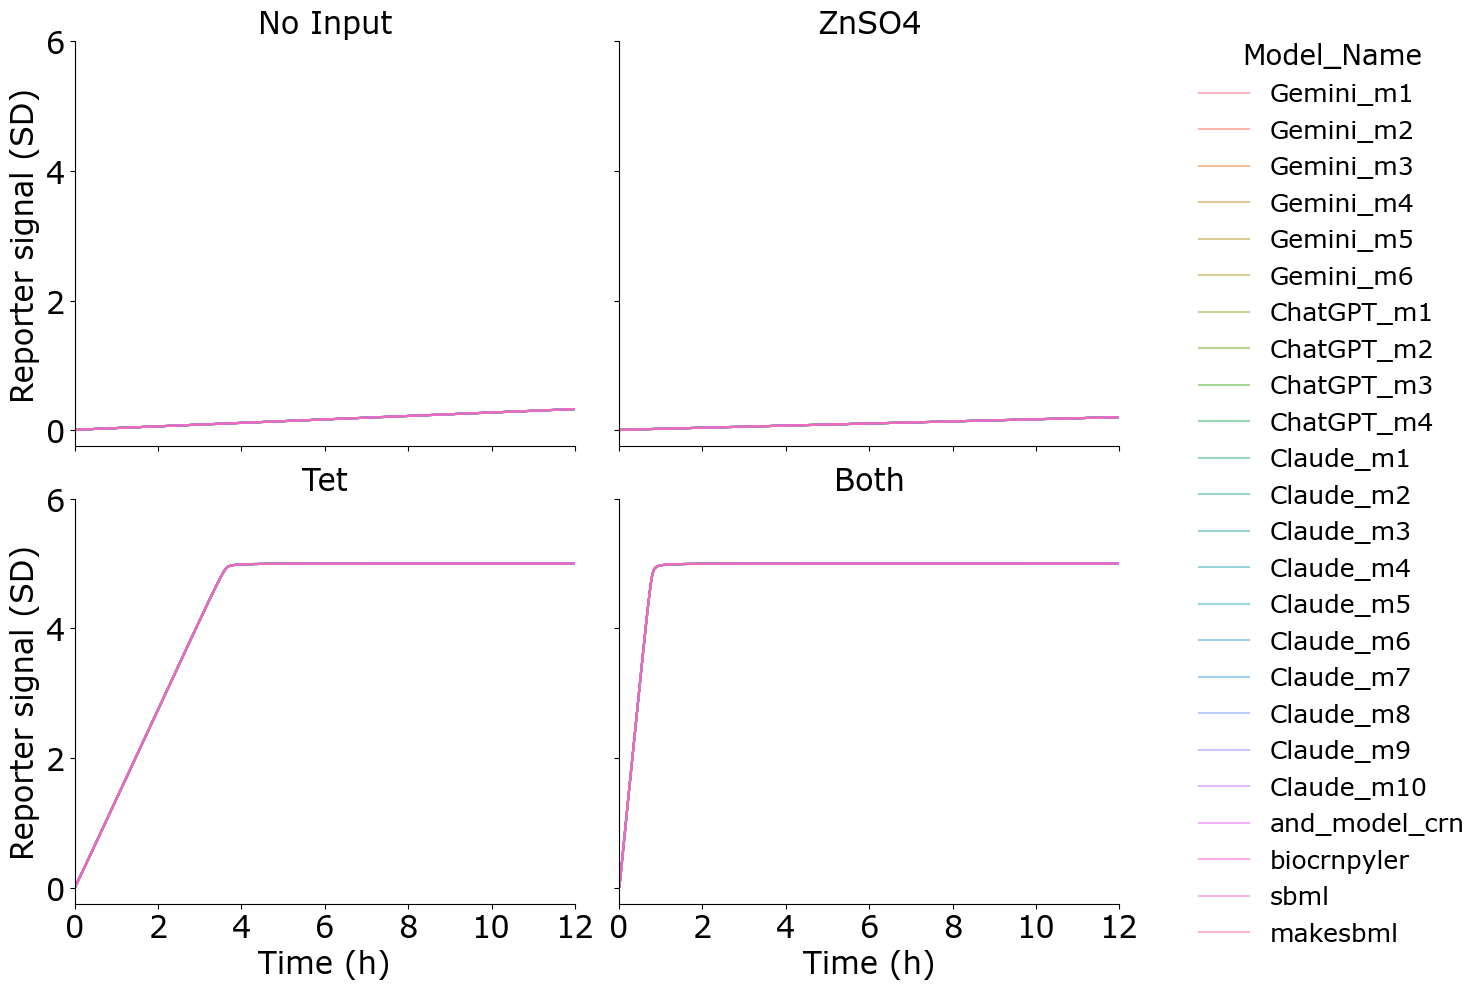

In [7]:
import seaborn as sns

# Convert Time from seconds to hours
all_simulation_df['Time (h)'] = all_simulation_df['Time'] / 3600

# Plotting
g = sns.relplot(
    data=all_simulation_df,
    x='Time (h)',
    y='Reporter_Concentration',
    hue='Model_Name',     
    col='Condition',      
    col_wrap=2,           
    kind='line',
    alpha=0.5,            
    height=5,            
    aspect=1            
)

# Formatting
fs = 22
ymin = -0.25
ymax = 6 

for ax in g.axes.flat:
    # Set labels
    ax.set_xlabel('Time (h)', fontsize=fs)
    ax.set_ylabel('Reporter signal (SD)', fontsize=fs)
    
    # Set limits
    ax.set_xlim(0, 12)
    ax.set_xticks(range(0, 13, 2))
    ax.set_ylim(ymin, ymax)
    
    # Set tick font sizes
    ax.tick_params(axis='both', which='major', labelsize=fs)

# Format the subplot titles 
g.set_titles(col_template="{col_name}", size=fs)
sns.move_legend(
    g, "center left", 
    bbox_to_anchor=(1.02, 0.5), 
    fontsize=18, 
    title_fontsize=20,
    frameon=False              
)

# Clean up layout
plt.tight_layout()
plt.show()


# Computing environment

In [8]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

